# 04.2 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/04-trustworthy-models/02-data-leakage/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail()                                   # ~1 s after the first run
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

def customer_table(cutoff, months=3):
    """One row per customer: features from before `cutoff`, churned = no order in the next `months`."""
    cutoff = pd.Timestamp(cutoff)
    past = sales[sales["InvoiceDate"] < cutoff]
    future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < cutoff + pd.DateOffset(months=months))]
    c = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                        products=("StockCode", "nunique"), country=("Country", "first"),
                                        first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
    c["tenure_days"] = (cutoff - c["first_order"]).dt.days
    c["days_since_last"] = (cutoff - c["last_order"]).dt.days
    came_back = future.groupby("Customer ID")["Revenue"].sum().reindex(c.index).fillna(0) > 0
    c["churned"] = (~came_back).astype(int)
    return c.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
cust = customer_table("2011-09-01")
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}")

# the column the old export "helpfully" added: days since last order, measured on the EXPORT date
export_date = sales["InvoiceDate"].max()
last_ever = sales.groupby("Customer ID")["InvoiceDate"].max()
cust["recency_days"] = (export_date - last_ever).dt.days.reindex(cust.index)
print("export date:", export_date.date())
cust[["days_since_last", "recency_days", "churned"]].head()

3,317 customers, churn rate 43.6%
export date: 2011-12-09


,days_since_last,recency_days,churned
Customer ID,,,
12346.0,225,325,1
12347.0,29,1,0
12348.0,148,74,0
12350.0,210,309,1
12352.0,162,35,0


## Exercise 1

- (a) **Yes.** Computed from orders before the cut-off.
- (b) **No.** "2011" includes September to December, the target window.
- (c) **No.** October is after the cut-off.
- (d) **Yes**, as long as it was recorded before the cut-off.
- (e) **Careful.** A table exported in December counts tickets filed after 1 Sep. Recompute it as "tickets before 1 Sep".
- (f) **Yes.**

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

cust["spend_2011"] = sales[sales["InvoiceDate"].dt.year == 2011].groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
for name, cols in [("honest features", features), ("+ spend_2011", features + ["spend_2011"])]:
    Xa, Xb, ya, yb = train_test_split(cust[cols], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
    print(f"{name:<16} test accuracy {DecisionTreeClassifier(max_depth=4, random_state=0).fit(Xa, ya).score(Xb, yb):.1%}")

honest features  test accuracy 65.1%
+ spend_2011     test accuracy 86.6%


`spend_2011` includes spending in the target window, so it leaks: accuracy jumps from 65.1% to 86.6%. Notice how innocent the name looks. "Spend this year" sounds like a perfectly normal customer feature; the leak is in the *date range*, not the column name.

## Exercise 2

In [3]:
leaky = features + ["recency_days"]
Xa, Xb, ya, yb = train_test_split(cust[leaky], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
m = DecisionTreeClassifier(max_depth=4, random_state=0).fit(Xa, ya)
print("importances:", pd.Series(m.feature_importances_, index=leaky).round(2).to_dict())
print("correlation with churned:")
print(cust[leaky + ["churned"]].corr()["churned"].drop("churned").round(2).sort_values())

importances: {'orders': 0.0, 'spend': 0.02, 'products': 0.0, 'tenure_days': 0.0, 'days_since_last': 0.0, 'recency_days': 0.98}
correlation with churned:
products          -0.26
orders            -0.25
tenure_days       -0.14
spend             -0.13
days_since_last    0.31
recency_days       0.81
Name: churned, dtype: float64


Both show it, but the importances are the loudest alarm: one feature with ~98% of the importance and a near-perfect score. A correlation table needs no model at all and is a good habit in EDA (01.9). Rule of thumb: **any single feature that predicts the target almost perfectly is guilty until proven innocent.**

## Exercise 3

{50: np.float64(0.5), 200: np.float64(0.72), 1000: np.float64(0.78), 5000: np.float64(0.73)}


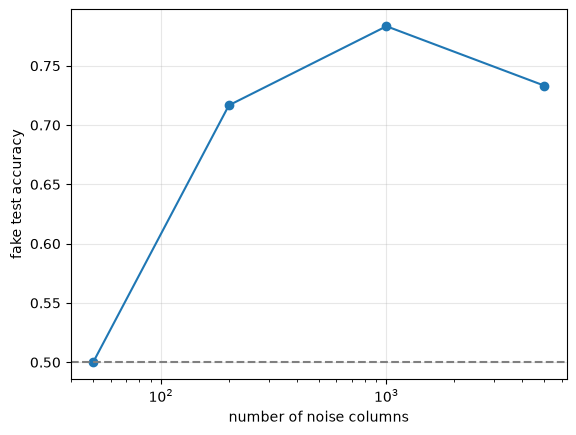

In [4]:
from sklearn.linear_model import LogisticRegression
rng = np.random.default_rng(0)
y_noise = rng.integers(0, 2, 200)
sizes, fake = [50, 200, 1000, 5000], []
for p in sizes:
    X = rng.normal(size=(200, p))
    corr = np.abs([np.corrcoef(X[:, j], y_noise)[0, 1] for j in range(p)])
    Xa, Xb, ya, yb = train_test_split(X[:, np.argsort(corr)[-20:]], y_noise, test_size=0.3, random_state=0)
    fake.append(LogisticRegression().fit(Xa, ya).score(Xb, yb))
print(dict(zip(sizes, np.round(fake, 2))))
plt.plot(sizes, fake, marker="o"); plt.xscale("log"); plt.axhline(0.5, ls="--", c="gray")
plt.xlabel("number of noise columns"); plt.ylabel("fake test accuracy"); plt.grid(alpha=.3); plt.show()

With 50 columns the fake accuracy is still at chance (50%); from a few hundred columns upwards it sits in the 70s (72%, 78%, 73% here; the exact value varies with luck). The more columns you search through with the test labels in view, the more chance correlations you find. Wide datasets (genetics, text, many engineered features) are where this leak bites hardest.

## Exercise 4

In [5]:
from sklearn.neighbors import KNeighborsClassifier
doubled = pd.concat([cust, cust.sample(frac=0.3, random_state=1)])
models = {"tree depth 3": DecisionTreeClassifier(max_depth=3, random_state=0),
          "tree unlimited": DecisionTreeClassifier(random_state=0),
          "1-nearest neighbour": KNeighborsClassifier(1)}
for name, m in models.items():
    scores = []
    for data in [cust, doubled]:
        Xa, Xb, ya, yb = train_test_split(data[features], data["churned"], test_size=0.25, random_state=0)
        scores.append(m.fit(Xa, ya).score(Xb, yb))
    print(f"{name:<20} clean {scores[0]:.1%}   duplicated {scores[1]:.1%}   gain {scores[1]-scores[0]:+.1%}")

tree depth 3         clean 69.3%   duplicated 67.3%   gain -2.0%
tree unlimited       clean 61.1%   duplicated 71.6%   gain +10.5%


1-nearest neighbour  clean 60.6%   duplicated 73.6%   gain +13.0%


The flexible models gain 10 to 13 points (unlimited tree +10.5, 1-NN +13.0), because they memorise individual rows, and a memorised twin is a free correct answer. The depth-3 tree can only learn a few broad rules, so the duplicates do not help it at all (here it even scores 2 points lower, just from the different split). Duplicates inflate exactly the models most likely to be overfitting anyway, which makes the inflated score doubly misleading.